# ZHAW BSc Data Science – Reinforcement Learning
## Week 03 - Graded Lab: Monte Carlo Methods vs. Q-Learning
### Frozen Lake Environment

**Authors:**
* Jonas Bratschi (`bratsjon`)
* Natalie Jakab (`jakabnat`)

---

### Project Overview & Educational Objectives
In this graded lab, we evaluate, implement, and compare model-free Reinforcement Learning algorithms on the Gymnasium `FrozenLake-v1` environment:

1. **Task 1 – Monte Carlo with a Random Policy**:
   * Evaluation of policy returns under random behavior.
   * Selection and justification of First-Visit vs. Every-Visit (Multiple-Visits) Monte Carlo estimation.
2. **Task 2 – Incremental Monte Carlo Control**:
   * Step-by-step update rule for value estimates without waiting for full batch completion across episodes.
   * Derivation of an $\varepsilon$-greedy policy balancing exploration and exploitation.
3. **Task 3 – Q-Learning Integration**:
   * Implementation of off-policy Temporal Difference control ($Q$-Learning).
   * Empirical performance and convergence comparison against Monte Carlo methods.
4. **Comparative Analysis & Benchmark**:
   * Trajectory length distributions and episode-wise learning curves.
   * State-value and action-value function estimation accuracy.
   * Generalization and scaling behavior on an enlarged $11 \times 11$ map.

## Create a Virtual Environment and Install Dependencies

In [9]:
%%bash
# Stop immediately if a command exits with a non-zero status
set -e

echo "=== Step 1: Locating Optimal Python Version ==="
# Python 3.11 is optimal for numpy 2.0.2, pandas 2.3.2, gymnasium 1.1.1, and pygame 2.6.1
PYTHON_BIN=""
for candidate in python3.11 python3.12 python3; do
    if command -v "$candidate" &> /dev/null; then
        PYTHON_BIN="$candidate"
        break
    fi
done

if [ -z "$PYTHON_BIN" ]; then
    echo "Error: No suitable python3 interpreter found in PATH."
    exit 1
fi

echo "Selected Python binary: $PYTHON_BIN ($($PYTHON_BIN --version))"

echo -e "\n=== Step 2: Creating Virtual Environment ==="
VENV_DIR=".venv"
if [ ! -d "$VENV_DIR" ]; then
    echo "Creating virtual environment in $VENV_DIR..."
    $PYTHON_BIN -m venv "$VENV_DIR"
else
    echo "Virtual environment already exists in $VENV_DIR."
fi

echo -e "\n=== Step 3: Upgrading pip and Installing Dependencies ==="
"$VENV_DIR/bin/pip" install --upgrade pip --quiet

if [ -f "requirements.txt" ]; then
    echo "Installing packages from requirements.txt..."
    "$VENV_DIR/bin/pip" install -r requirements.txt --quiet
    echo "Dependencies successfully installed."
else
    echo "Warning: requirements.txt not found in current directory."
fi

echo -e "\n=== Step 4: Registering Jupyter Kernel ==="
"$VENV_DIR/bin/python" -m ipykernel install --user --name=rl-week03 --display-name="Python (RL Week 03)"

echo -e "\n=== Setup Complete! ==="
echo "Please reload or select kernel: 'Python (RL Week 03)' in your Jupyter toolbar."

=== Step 1: Locating Optimal Python Version ===
Selected Python binary: python3.12 (Python 3.12.13)

=== Step 2: Creating Virtual Environment ===
Virtual environment already exists in .venv.

=== Step 3: Upgrading pip and Installing Dependencies ===
Installing packages from requirements.txt...
Dependencies successfully installed.

=== Step 4: Registering Jupyter Kernel ===
Installed kernelspec rl-week03 in /Users/jonas/Library/Jupyter/kernels/rl-week03

=== Setup Complete! ===
Please reload or select kernel: 'Python (RL Week 03)' in your Jupyter toolbar.


## Verify Environment and Core Libraries

In [10]:
import sys
from pathlib import Path
from typing import NamedTuple

import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# Configure visualization settings
sns.set_theme()
%matplotlib inline

# Verify environment and core libraries
print(f"Python Executable: {sys.executable}")
print(f"Python Version:    {sys.version.split()[0]}")
print(f"NumPy Version:     {np.__version__}")
print(f"Pandas Version:    {pd.__version__}")
print(f"Gymnasium Version: {gym.__version__}")

Python Executable: /Users/jonas/Documents/GitHub/ZHAW/Semester 7/RL/Graded Lab 1/.venv/bin/python
Python Version:    3.12.13
NumPy Version:     2.0.2
Pandas Version:    2.3.2
Gymnasium Version: 1.1.1


## Frozen Lake Environment Setup

Environment successfully initialized!
Map Size:       4x4
State Space:    16 discrete states (0 to 15)
Action Space:   4 discrete actions (0: Left, 1: Down, 2: Right, 3: Up)
Is Slippery:    True


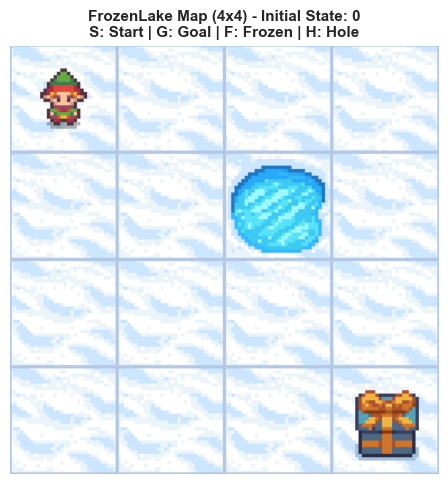

In [11]:
# =====================================================================
# Environment Configuration & Parameter Setup
# =====================================================================

class Params(NamedTuple):
    total_episodes: int   # Number of training episodes
    learning_rate: float  # Step size / learning rate (alpha)
    gamma: float          # Discount factor
    epsilon: float        # Exploration rate for epsilon-greedy
    map_size: int         # Grid size (e.g., 4 for 4x4, 11 for 11x11)
    seed: int             # PRNG seed for reproducibility
    is_slippery: bool     # Stochastic transitions (1/3 intended, 2/3 orthogonal)
    n_runs: int           # Independent repetitions to account for stochasticity
    action_size: int      # Discrete action space dimension
    state_size: int       # Discrete state / observation space dimension
    proba_frozen: float   # Probability of frozen tile generation
    savefig_folder: Path  # Output directory for evaluation plots


# Base configuration for initial experiments
params = Params(
    total_episodes=2000,
    learning_rate=0.8,
    gamma=0.95,
    epsilon=0.1,
    map_size=4,           # Start with standard 4x4, scale to 11x11 later
    seed=123,
    is_slippery=True,
    n_runs=20,
    action_size=None,     # Derived dynamically below
    state_size=None,      # Derived dynamically below
    proba_frozen=0.9,
    savefig_folder=Path("./_static/img"),
)

# Ensure output directory exists
params.savefig_folder.mkdir(parents=True, exist_ok=True)

# Generate reproducible environment instance
env = gym.make(
    "FrozenLake-v1",
    is_slippery=params.is_slippery,
    render_mode="rgb_array",
    desc=generate_random_map(
        size=params.map_size,
        p=params.proba_frozen,
        seed=params.seed
    ),
)

# Populate space dimensions dynamically
params = params._replace(
    action_size=int(env.action_space.n),
    state_size=int(env.observation_space.n)
)

print(f"Environment successfully initialized!")
print(f"Map Size:       {params.map_size}x{params.map_size}")
print(f"State Space:    {params.state_size} discrete states (0 to {params.state_size - 1})")
print(f"Action Space:   {params.action_size} discrete actions (0: Left, 1: Down, 2: Right, 3: Up)")
print(f"Is Slippery:    {params.is_slippery}")

# Reset environment to place the agent at the initial state (S)
initial_state, info = env.reset(seed=params.seed)

# Render and plot the environment map with initial agent position
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(env.render())
ax.axis("off")
ax.set_title(
    f"FrozenLake Map ({params.map_size}x{params.map_size}) - Initial State: {initial_state}\n"
    f"S: Start | G: Goal | F: Frozen | H: Hole",
    fontsize=11,
    fontweight="bold"
)
plt.tight_layout()
fig.savefig(params.savefig_folder / f"frozenlake_initial_map_{params.map_size}x{params.map_size}.png", dpi=300)
plt.show()

## Task 1 – Monte Carlo with a Random Policy

### Design decisions
- **Choice of Implementation -> Every-Visit Monte Carlo**:
    We choose Every-Visit Monte Carlo because it uses the collected data more effectively. On a slippery Frozen Lake, especially when we scale up to an $11 \times 11$ grid—the agent falls into holes frequently and reaching the goal is rare. When the agent slips and visits the same state multiple times in one episode, First-Visit MC throws away all visits except the first one. Every-Visit MC updates the state every time it is visited. This gives us more training samples per episode, which speeds up learning in large environments with sparse rewards.

In [11]:
class MonteCarloRandomPolicy():
    """
    Monte Carlo evaluation of a random policy in the Frozen Lake environment.
    This implementation uses Every-Visit Monte Carlo estimation to update state-value estimates.
    """

    def __init__(self, env: gym.Env, params: Params):
        self.env = env
        self.params = params
        self.gamma = params.gamma
        self.state_value = np.zeros(self.params.state_size)  # Initialize state-value function
        self.returns_sum = np.zeros(self.params.state_size)    # Sum of returns for each state
        self.returns_count = np.zeros(self.params.state_size)  # Count of returns for each state

    def reset(self):
        """
        Reset state-value table and return tracking accumulators.
        """
        self.state_value = np.zeros(self.params.state_size)
        self.returns_sum = np.zeros(self.params.state_size)
        self.returns_count = np.zeros(self.params.state_size)

    def choose_action(self, state: int) -> int:
        """
        Choose an action uniformly at random from the action space.
        """
        return int(self.env.action_space.sample())

    def update_state_value(self, episode: list):
        """
        Update state-value estimates using Every-Visit Monte Carlo.
        Each state in the episode is updated with the return from that point to the end of the episode.
        """
        G = 0  # Initialize return
        # Reverse the episode to calculate returns from the end to the beginning
        for t in reversed(range(len(episode))):
            state, action, reward = episode[t]
            G = self.gamma * G + reward  # Update return
            # Update every-visit returns
            self.returns_sum[state] += G
            self.returns_count[state] += 1
            self.state_value[state] = self.returns_sum[state] / self.returns_count[state]  # Update state-value estimate

In [ ]:
def run_monte_carlo_random_policy(env: gym.Env, params: Params):
    """
    Run Monte Carlo evaluation of a random policy for a specified number of episodes.
    Returns the state-value estimates after training.
    """
    rewards = np.zeros((params.total_episodes, params.n_runs))
    steps = np.zeros((params.total_episodes, params.n_runs))
    episodes = np.arange(params.total_episodes)
    state_values = np.zeros((params.n_runs, params.state_size))

    agent = MonteCarloRandomPolicy(env, params)

    for run in range(self.params.n_runs):
            self.reset()
            run_seed = self.params.seed + run
